# GM12878 allelic effect prediction
Compare five models on the fixed FDR10-positive / matched-negative pilot benchmark, using the plotting conventions and peak stratification of `dsQTL_benchmark10.ipynb`.

All 546 source FDR10 positives are retained, including 51 that fail the equal-dosage restriction, along with 2,378 selected controls. FDR10 denotes source statistical evidence, not independently validated ground truth. Controls are selected for adequate coverage and near-balanced allelic counts, then matched within peak category and on coverage, accessibility, and observation count; these are not random genome-wide negatives. Some positives have fewer than five controls.

The first comparison uses each run's existing score. The second uses central 500–512 bp and **log2((ALT sum + 1) / (REF sum + 1))**. Binary classification uses the absolute value: imbalance can favor either allele. This notebook reads saved predictions and Atlas results; it does not run models or call the Atlas API.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
ROOT = Path('/data1/lesliec/sarthak/caduceus')
DATA = Path('/data1/lesliec/sarthak/data/allelic_imbalance')
INPUT = DATA / 'gm12878_all_positives_v2/benchmark.tsv'
PEAKS = ROOT / 'notebooks/benchmarks/dsqtl/dsQTL_benchmark8_cache/gm12878_merged.tsv.gz'
RUNS = {
    'cis-Mamba': 'cismamba_gm12878_14156853',
    'AlphaGenome Atlas': 'atlas_14157206',
    'Borzoi': 'borzoi_14157208',
    'Enformer': 'enformer_14157209',
    'EpiBERT': 'epibert_14157210',
}
COLORS = dict(zip(RUNS, ['#2878B5', '#4C3B92', '#55A868', '#DD8452', '#C44E52']))
v = pd.read_csv(INPUT, sep='\t')
assert len(v) == 2924 and v.label.sum() == 546
assert v.variant_id.is_unique
input_sha256 = hashlib.sha256(INPUT.read_bytes()).hexdigest()
tables, manifests, profiles = {}, {}, {}
for name, directory in RUNS.items():
    path = DATA / 'predictions' / directory
    table = pd.read_csv(path / 'scores.tsv', sep='\t')
    manifest = json.loads((path / 'run.json').read_text())
    assert manifest.get('input_sha256', manifest.get('variants_sha256')) == input_sha256, name
    for column in ['variant_id', 'ref', 'alt', 'label']:
        np.testing.assert_array_equal(table[column], v[column], err_msg=name + ': ' + column)
    tables[name], manifests[name] = table, manifest
    if name != 'AlphaGenome Atlas':
        profiles[name] = np.load(path / 'predictions.npy', mmap_mode='r')
        assert profiles[name].shape[0] == len(v) and profiles[name].shape[2] == 2
print(f'Validated {len(v):,} aligned rows for all {len(RUNS)} models. SHA256: {input_sha256}')

Validated 2,924 aligned rows for all 5 models. SHA256: f672cb0d146931c1a2d50ac71b069ec1d1e36e9002261146c0e74bc68f856a86


## Peak stratification
Recompute overlap against the same cached GM12878 merged peaks used by benchmark 10, and verify the benchmark annotations. Generic peaks have breadth **>68 experimental tracks**; relatively cell-type-specific peaks have breadth **≤68**. Track breadth includes replicates and does not imply exclusive activity in GM12878. This is stratification of GM12878 variants, not evaluation of other cell types.

Variants outside GM12878 peaks remain in the overall analysis, but not the two peak-category panels. Average precision depends on the sampled positive fraction; the dotted lines show each subset's baseline.

In [2]:
peaks = pd.read_csv(PEAKS, sep='\t')
assert set(peaks.median_breadth.dropna().unique()) == {68}
category = np.full(len(v), 'outside_GM12878_peaks', dtype=object)
for chrom, rows in v.groupby('chrom'):
    p = peaks.loc[peaks.chrom == chrom].sort_values('start')
    if p.empty:
        continue
    assert np.all(p.start.to_numpy()[1:] >= p.end.to_numpy()[:-1])
    positions = rows.pos0.to_numpy()
    idx = np.searchsorted(p.start.to_numpy(), positions, side='right') - 1
    overlaps = (idx >= 0) & (positions < p.end.to_numpy()[np.maximum(idx, 0)])
    category[rows.index[overlaps]] = p.specificity.to_numpy()[idx[overlaps]]
np.testing.assert_array_equal(category, v.specificity.to_numpy())
y = v.label.to_numpy(dtype=int)
MASKS = {
    'Overall': np.ones(len(v), dtype=bool),
    'Generic': category == 'low_specificity',
    'Cell-type-specific': category == 'high_specificity',
}
counts = pd.DataFrame([
    {'Subset': group, 'Variants': int(mask.sum()), 'Positives': int(y[mask].sum()),
     'Negatives': int((1-y[mask]).sum()), 'Chance AP': y[mask].mean()}
    for group, mask in MASKS.items()
]).set_index('Subset')
display(counts)
display(pd.crosstab(v.specificity, v.label).rename(columns={0: 'Negatives', 1: 'Positives'}))

,Variants,Positives,Negatives,Chance AP
Subset,,,,
Overall,2924,546,2378,0.186731
Generic,2646,469,2177,0.177249
Cell-type-specific,268,68,200,0.253731


label,Negatives,Positives
specificity,,
high_specificity,200,68
low_specificity,2177,469
outside_GM12878_peaks,1,9


## Existing scoring windows
These reproduce the stored run scores and intentionally preserve their different windows and scoring definitions. GM12878 tracks are used throughout; EpiBERT predicts **ATAC accessibility**, whereas the other models supply DNase predictions. AlphaGenome uses **precomputed Atlas** scores only.

In [3]:
native_definitions = pd.DataFrame([
    ['cis-Mamba', 'DNase', 500, 'log2(ALT mean / REF mean)', '0:500'],
    ['AlphaGenome Atlas', 'DNase', 501, 'log2((ALT sum + 1) / (REF sum + 1))', 'Atlas native'],
    ['Borzoi', 'DNase', 2048, 'log2(ALT sum / REF sum)', '3040:3104'],
    ['Enformer', 'DNase', 2048, 'log2(ALT sum / REF sum)', '440:456'],
    ['EpiBERT', 'ATAC', 512, 'ALT sum - REF sum', '2044:2048'],
], columns=['Model', 'Assay', 'Window bp', 'Signed score', 'Output bins [start:stop]']).set_index('Model')
display(native_definitions)
native_signed = pd.DataFrame({
    name: table['pred_log2_alt_ref' if name == 'cis-Mamba' else 'primary_signed_score'].to_numpy()
    for name, table in tables.items()
}, index=v.variant_id)
assert np.isfinite(native_signed.to_numpy()).all()
# Verify stored scores against saved REF/ALT profiles and the documented windows.
for name, start, stop in [('cis-Mamba', 0, 500), ('Borzoi', 3040, 3104),
                          ('Enformer', 440, 456), ('EpiBERT', 2044, 2048)]:
    sums = profiles[name][:, start:stop, :].sum(axis=1, dtype=np.float64)
    reproduced = sums[:, 1] - sums[:, 0] if name == 'EpiBERT' else np.log2(sums[:, 1] / sums[:, 0])
    np.testing.assert_allclose(reproduced, native_signed[name], rtol=1e-5, atol=1e-6, err_msg=name)
np.testing.assert_allclose(native_signed['AlphaGenome Atlas'], tables['AlphaGenome Atlas'].atlas_score)
print('All existing scores are finite and their definitions verified.')

,Assay,Window bp,Signed score,Output bins [start:stop]
Model,,,,
cis-Mamba,DNase,500,log2(ALT mean / REF mean),0:500
AlphaGenome Atlas,DNase,501,log2((ALT sum + 1) / (REF sum + 1)),Atlas native
Borzoi,DNase,2048,log2(ALT sum / REF sum),3040:3104
Enformer,DNase,2048,log2(ALT sum / REF sum),440:456
EpiBERT,ATAC,512,ALT sum - REF sum,2044:2048


All existing scores are finite and their definitions verified.


Existing scores: average precision


,Overall,Generic,Cell-type-specific
AlphaGenome Atlas,0.5776,0.5709,0.6173
Enformer,0.4996,0.4943,0.5527
Borzoi,0.4713,0.4736,0.4608
cis-Mamba,0.4277,0.4258,0.4564
EpiBERT,0.3502,0.3512,0.3706


Existing scores: AUROC


,Overall,Generic,Cell-type-specific
AlphaGenome Atlas,0.7856,0.7883,0.7490
Enformer,0.7545,0.7637,0.7032
Borzoi,0.7379,0.7458,0.6404
cis-Mamba,0.6984,0.7074,0.6273
EpiBERT,0.6314,0.6472,0.5375


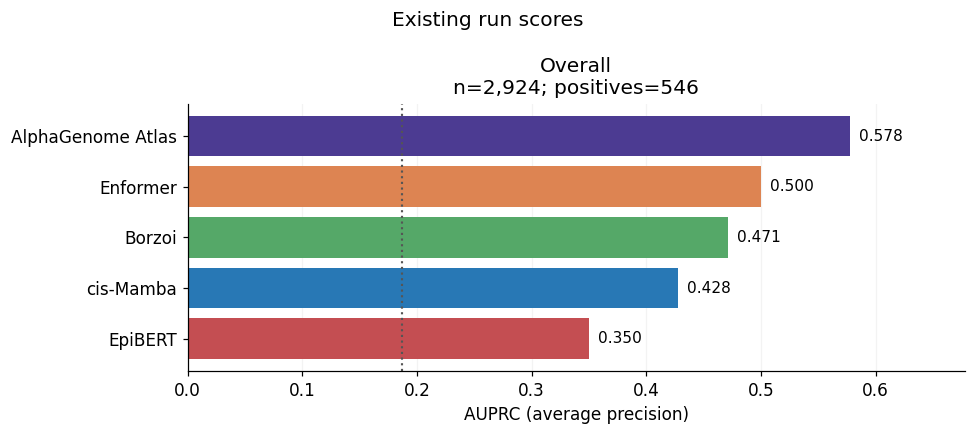

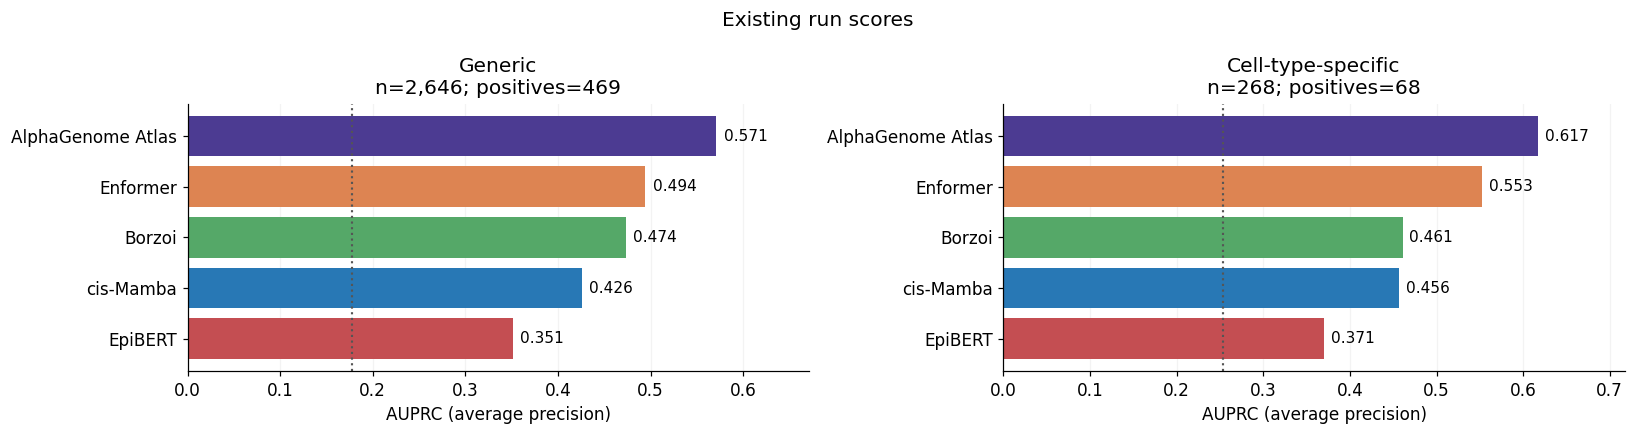

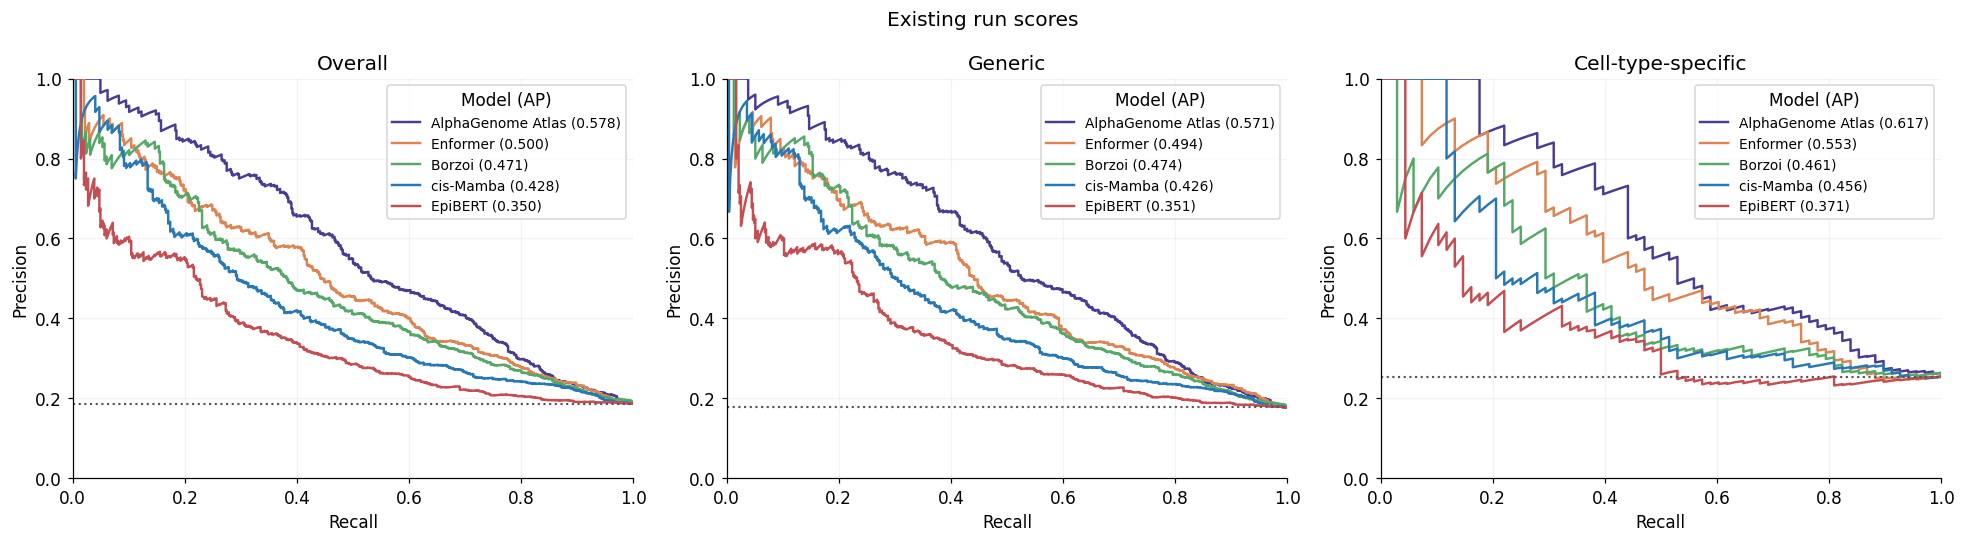

In [4]:
def metrics(signed):
    assert signed.index.equals(pd.Index(v.variant_id))
    assert np.isfinite(signed.to_numpy()).all()  # Never silently change the cohort by model.
    ap = pd.DataFrame(index=signed.columns, columns=MASKS, dtype=float)
    auroc = ap.copy()
    for name in signed:
        score = signed[name].abs().to_numpy()
        for group, mask in MASKS.items():
            ap.loc[name, group] = average_precision_score(y[mask], score[mask])
            auroc.loc[name, group] = roc_auc_score(y[mask], score[mask])
    return ap.sort_values('Overall', ascending=False), auroc

def comparison_plots(signed, ap, title):
    order = list(ap.index)
    def bars(ax, group):
        values = ap.loc[order, group].to_numpy()
        ax.barh(np.arange(len(order)), values, color=[COLORS[name] for name in order])
        ax.set_yticks(np.arange(len(order)), order)
        ax.invert_yaxis()
        ax.axvline(counts.loc[group, 'Chance AP'], color='#555555', ls=':', lw=1.4)
        ax.set_xlim(0, min(1, max(float(values.max()), counts.loc[group, 'Chance AP']) + .10))
        for i, value in enumerate(values):
            ax.text(value + .008, i, f'{value:.3f}', va='center', fontsize=10)
        ax.set_xlabel('AUPRC (average precision)')
        ax.set_title(f"{group}\nn={counts.loc[group, 'Variants']:,}; positives={counts.loc[group, 'Positives']:,}")
        ax.grid(axis='x', alpha=.15)
        ax.set_axisbelow(True)
    fig, ax = plt.subplots(figsize=(9, 4))
    bars(ax, 'Overall')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    for ax, group in zip(axes, ['Generic', 'Cell-type-specific']):
        bars(ax, group)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (group, mask) in zip(axes, MASKS.items()):
        for name in order:
            precision, recall, _ = precision_recall_curve(y[mask], signed[name].abs().to_numpy()[mask])
            ax.plot(recall, precision, color=COLORS[name], lw=1.6,
                    label=f'{name} ({ap.loc[name, group]:.3f})')
        ax.axhline(counts.loc[group, 'Chance AP'], color='#555555', ls=':', lw=1.4)
        ax.set(xlabel='Recall', ylabel='Precision', title=group, xlim=(0, 1), ylim=(0, 1))
        ax.legend(fontsize=9, title='Model (AP)')
        ax.grid(alpha=.15)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

native_ap, native_auroc = metrics(native_signed)
print('Existing scores: average precision')
display(native_ap.round(4))
print('Existing scores: AUROC')
display(native_auroc.loc[native_ap.index].round(4))
comparison_plots(native_signed, native_ap, 'Existing run scores')

## Central 500–512 bp, with a pseudocount of 1
For saved profiles, sum the central output bins separately for REF and ALT, then calculate:

`log2((ALT sum + 1) / (REF sum + 1))`

The pseudocount is added **after summing**, not to each bin or to an averaged profile. cis-Mamba supplies 500 single-base values; Borzoi uses 16 × 32 bp bins; Enformer and EpiBERT use 4 × 128 bp bins. Atlas already supplies the requested 501 bp score, so reuse it unchanged without adding a second pseudocount. All slicing below is zero-based, stop-exclusive.

The windows and formula are comparable, but model output units, input contexts, and assays remain different. Adding one does not calibrate their output scales.

,Output bins,Bin bp,Window bp
Model,,,
cis-Mamba,0:500,1,500
AlphaGenome Atlas,Native Atlas score,1,501
Borzoi,3064:3080,32,512
Enformer,446:450,128,512
EpiBERT,2044:2048,128,512


Central windows + pseudocount 1: average precision


,Overall,Generic,Cell-type-specific
AlphaGenome Atlas,0.5776,0.5709,0.6173
EpiBERT,0.5190,0.5126,0.5568
Enformer,0.4897,0.4875,0.5446
Borzoi,0.4829,0.4858,0.4735
cis-Mamba,0.4273,0.4255,0.4564


Central windows + pseudocount 1: AUROC


,Overall,Generic,Cell-type-specific
AlphaGenome Atlas,0.7856,0.7883,0.7490
EpiBERT,0.7384,0.7441,0.6840
Enformer,0.7334,0.7448,0.6888
Borzoi,0.7287,0.7370,0.6445
cis-Mamba,0.6978,0.7070,0.6267


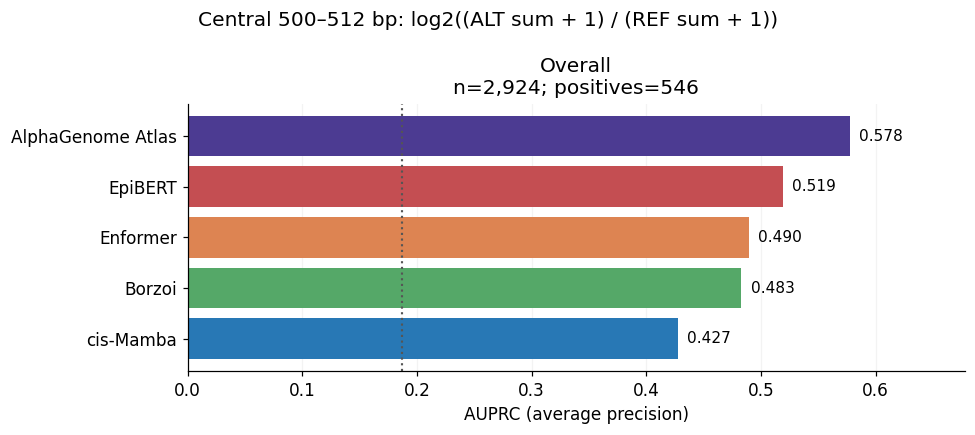

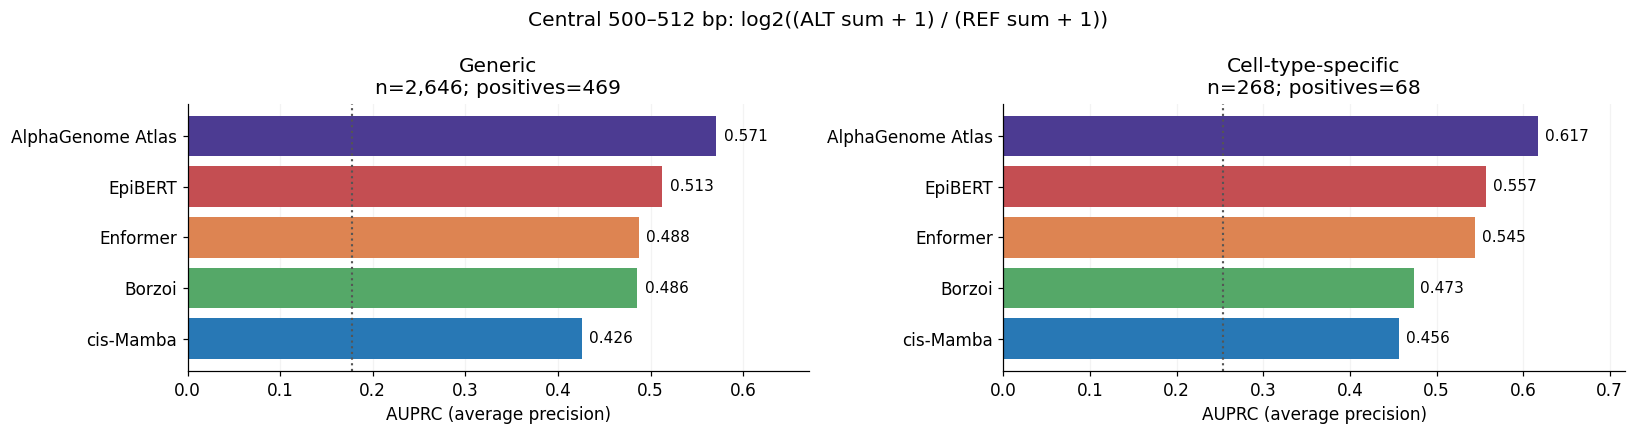

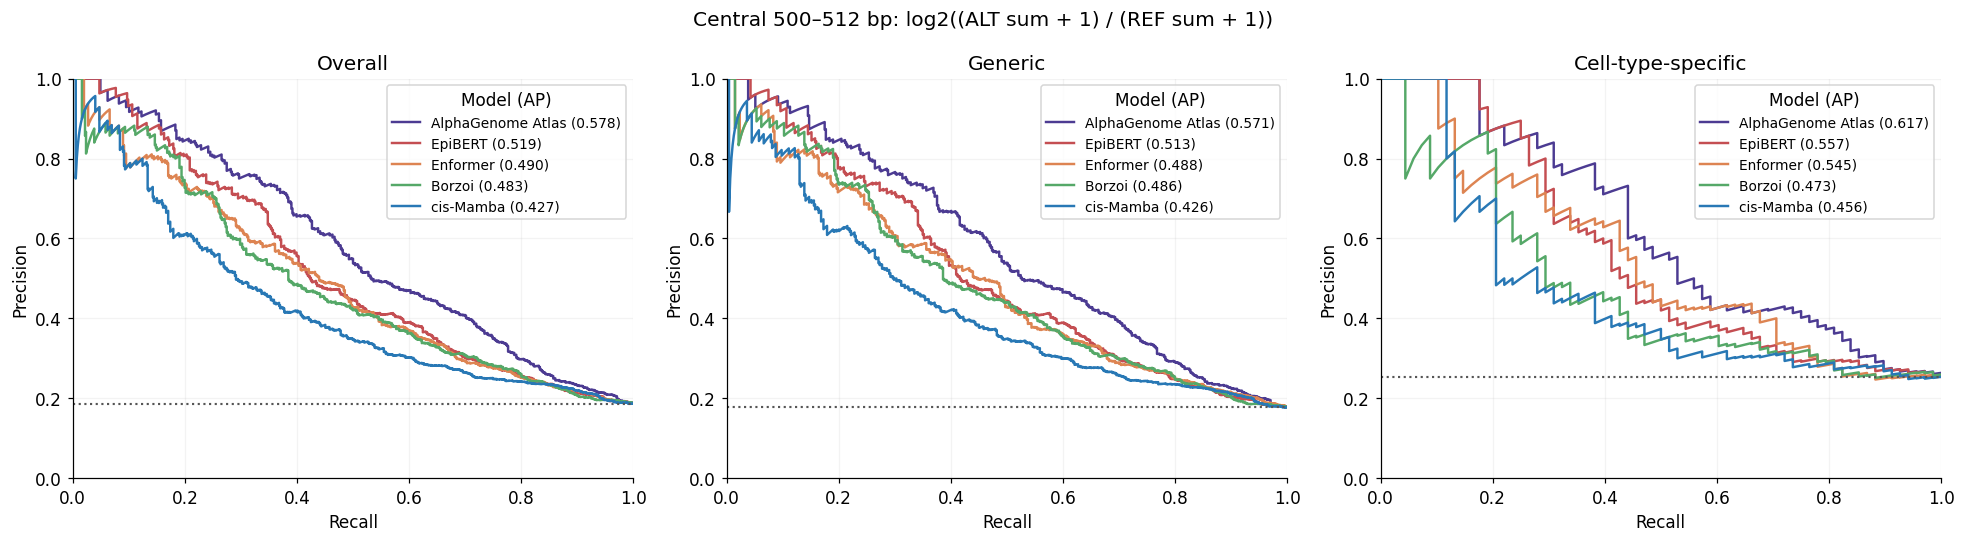

In [5]:
WINDOWS = {
    'cis-Mamba': (0, 500, 1),
    'Borzoi': (3064, 3080, 32),
    'Enformer': (446, 450, 128),
    'EpiBERT': (2044, 2048, 128),
}
central_signed = pd.DataFrame(index=v.variant_id)
window_rows = []
for name in RUNS:
    if name == 'AlphaGenome Atlas':
        central_signed[name] = tables[name].atlas_score.to_numpy()
        window_rows.append([name, 'Native Atlas score', 1, 501])
        continue
    start, stop, bin_bp = WINDOWS[name]
    profile = profiles[name]
    assert start + stop == profile.shape[1], (name, profile.shape)  # Symmetric center.
    central = profile[:, start:stop, :]
    assert np.isfinite(central).all() and (central >= 0).all(), name
    sums = central.sum(axis=1, dtype=np.float64)  # axis 2 is REF, ALT.
    central_signed[name] = np.log2((sums[:, 1] + 1.0) / (sums[:, 0] + 1.0))
    window_rows.append([name, f'{start}:{stop}', bin_bp, (stop-start)*bin_bp])
assert np.isfinite(central_signed.to_numpy()).all()
np.testing.assert_array_equal(central_signed['AlphaGenome Atlas'], native_signed['AlphaGenome Atlas'])
display(pd.DataFrame(window_rows, columns=['Model', 'Output bins', 'Bin bp', 'Window bp']).set_index('Model'))
central_ap, central_auroc = metrics(central_signed)
print('Central windows + pseudocount 1: average precision')
display(central_ap.round(4))
print('Central windows + pseudocount 1: AUROC')
display(central_auroc.loc[central_ap.index].round(4))
comparison_plots(central_signed, central_ap, 'Central 500–512 bp: log2((ALT sum + 1) / (REF sum + 1))')

In [6]:
print('Change in average precision: central windows minus existing scores')
display((central_ap - native_ap).loc[central_ap.index].round(4))
# In-memory row-level results for subsequent analyses; original files remain unchanged.
scored_variants = v.copy()
for name in RUNS:
    scored_variants[name + ' | existing signed'] = native_signed[name].to_numpy()
    scored_variants[name + ' | central signed'] = central_signed[name].to_numpy()
print(f'Completed both comparisons on all {len(scored_variants):,} variants; no missing-score exclusions.')

Change in average precision: central windows minus existing scores


,Overall,Generic,Cell-type-specific
AlphaGenome Atlas,0.0000,0.0000,0.0000
EpiBERT,0.1688,0.1614,0.1862
Enformer,-0.0099,-0.0067,-0.0082
Borzoi,0.0117,0.0122,0.0127
cis-Mamba,-0.0004,-0.0003,-0.0000


Completed both comparisons on all 2,924 variants; no missing-score exclusions.


## Interpretation and next steps
This is an exploratory binary benchmark against deliberately well-balanced controls. Its AP reflects this selected cohort and should not be interpreted as genome-wide precision. The small cell-type-specific subset has only 68 positives, so small differences in model rank need uncertainty estimates before making strong claims.

A subsequent direction-accuracy analysis should use signed scores and an explicitly allele-oriented observed effect, with unequal-dosage positives handled separately. Additional checks can include uncertainty estimates accounting for shared loci/matched controls, sensitivity to control selection and pseudocount, and verification of the source FDR procedure. These are separate from the requested binary comparison.

## Peak overlap and observed versus predicted allelic effects
Most source positives overlap this GM12878 peak set: **537/546 (98.35%)**; **9/546 (1.65%)** are outside. “Outside” refers to this particular merged peak annotation, not proof of absent accessibility in every experiment.

The observed x-axis is **log2((ALT reads + 1)/(REF reads + 1))** from each variant's highest-coverage available GM12878 sample (the benchmark's representative sample). This is an observed allelic read ratio, not a causal, dosage-corrected effect estimate. We do not reinterpret the source `logit_es` field. All positives are retained; an equal-dosage sensitivity correlation is reported separately. The y-axis uses the central-window signed prediction above, so positive values on either axis favor ALT.

Color denotes absolute distance to the nearest annotated **transcript TSS**, using the local GRCh38 GENCODE v44 annotation packaged with the 10x 2024-A reference. All transcript TSSs in that file are eligible, without a GM12878 expression filter. GTF coordinates are converted from 1-based inclusive to 0-based; plus-strand TSS = start − 1, minus-strand TSS = end − 1. Color is logarithmic in distance + 1, shared across models and plots. This distance does not establish the target gene.

In [ ]:
import gzip
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from scipy.stats import spearmanr

inside = v.specificity.ne('outside_GM12878_peaks').to_numpy()
overlap_table = pd.crosstab(
    pd.Series(np.where(y == 1, 'FDR10 positive', 'Matched negative'), name='Label'),
    pd.Series(np.where(inside, 'Inside GM12878 peaks', 'Outside GM12878 peaks'), name='Peak overlap')
)
overlap_table['Outside (%)'] = 100 * overlap_table['Outside GM12878 peaks'] / overlap_table.sum(axis=1)
display(overlap_table)
display(v.loc[~inside, ['rsid', 'chrom', 'pos0', 'label', 'ref_counts', 'alt_counts', 'BAD']])

GTF = Path('/data1/lesliec/sarthak/data/references/refdata-gex-GRCh38-2024-A/genes/genes.gtf.gz')
tss_lists = {}
with gzip.open(GTF, 'rt') as handle:
    for line in handle:
        if line.startswith('#'):
            continue
        fields = line.rstrip().split('\t')
        if fields[2] != 'transcript' or fields[6] not in ('+', '-'):
            continue
        coordinate = int(fields[3] if fields[6] == '+' else fields[4]) - 1
        tss_lists.setdefault(fields[0], []).append(coordinate)
tss_by_chrom = {chrom: np.unique(coords) for chrom, coords in tss_lists.items()}
nearest_tss = np.full(len(v), -1, dtype=np.int64)
for chrom, rows in v.groupby('chrom'):
    assert chrom in tss_by_chrom, f'No annotated TSSs for {chrom}'
    sites = tss_by_chrom[chrom]
    positions = rows.pos0.to_numpy()
    idx = np.searchsorted(sites, positions)
    left = sites[np.clip(idx - 1, 0, len(sites) - 1)]
    right = sites[np.clip(idx, 0, len(sites) - 1)]
    nearest_tss[rows.index] = np.where(abs(positions-left) <= abs(positions-right), left, right)
assert (nearest_tss >= 0).all()
tss_distance = np.abs(v.pos0.to_numpy() - nearest_tss)
observed_signed = np.log2((v.alt_counts.to_numpy(dtype=float) + 1) /
                          (v.ref_counts.to_numpy(dtype=float) + 1))
assert np.isfinite(observed_signed).all()
scored_variants['observed_log2_alt_ref_pc1'] = observed_signed
scored_variants['nearest_transcript_tss_pos0'] = nearest_tss
scored_variants['distance_to_tss_bp'] = tss_distance
print(f'TSS annotation: {GTF}')
print(f'{sum(map(len, tss_by_chrom.values())):,} unique chromosome/TSS sites; distances computed for all {len(v):,} variants.')
display(scored_variants.groupby('label').distance_to_tss_bp.describe())

Peak overlap,Inside GM12878 peaks,Outside GM12878 peaks,Outside (%)
Label,,,
FDR10 positive,537,9,1.648352
Matched negative,2377,1,0.042052


,rsid,chrom,pos0,label,ref_counts,alt_counts,BAD
23,rs10743298,chr12,18982481,1,23,5,1.0
25,rs1076572,chr16,3180586,1,28,8,1.0
38,rs10993241,chr9,94554605,1,5,31,1.0
39,rs10993242,chr9,94554667,1,2,23,1.0
198,rs2278002,chr5,22214242,1,1,15,1.0
283,rs3924174,chr2,62303363,1,4,24,1.0
349,rs57347337,chr1,187072694,1,2,17,1.0
416,rs6953326,chr7,7259399,1,6,25,1.0
441,rs72720636,chr14,57366114,1,30,4,1.0
1323,rs216357,chr9,33808348,0,28,24,1.0


TSS annotation: /data1/lesliec/sarthak/data/references/refdata-gex-GRCh38-2024-A/genes/genes.gtf.gz
193,226 unique chromosome/TSS sites; distances computed for all 2,924 variants.


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,2378.0,9889.320437,33000.978360,0.0,113.25,612.0,8343.75,844806.0
1,546.0,21727.329670,73064.447513,2.0,296.00,4289.5,19743.25,847701.0


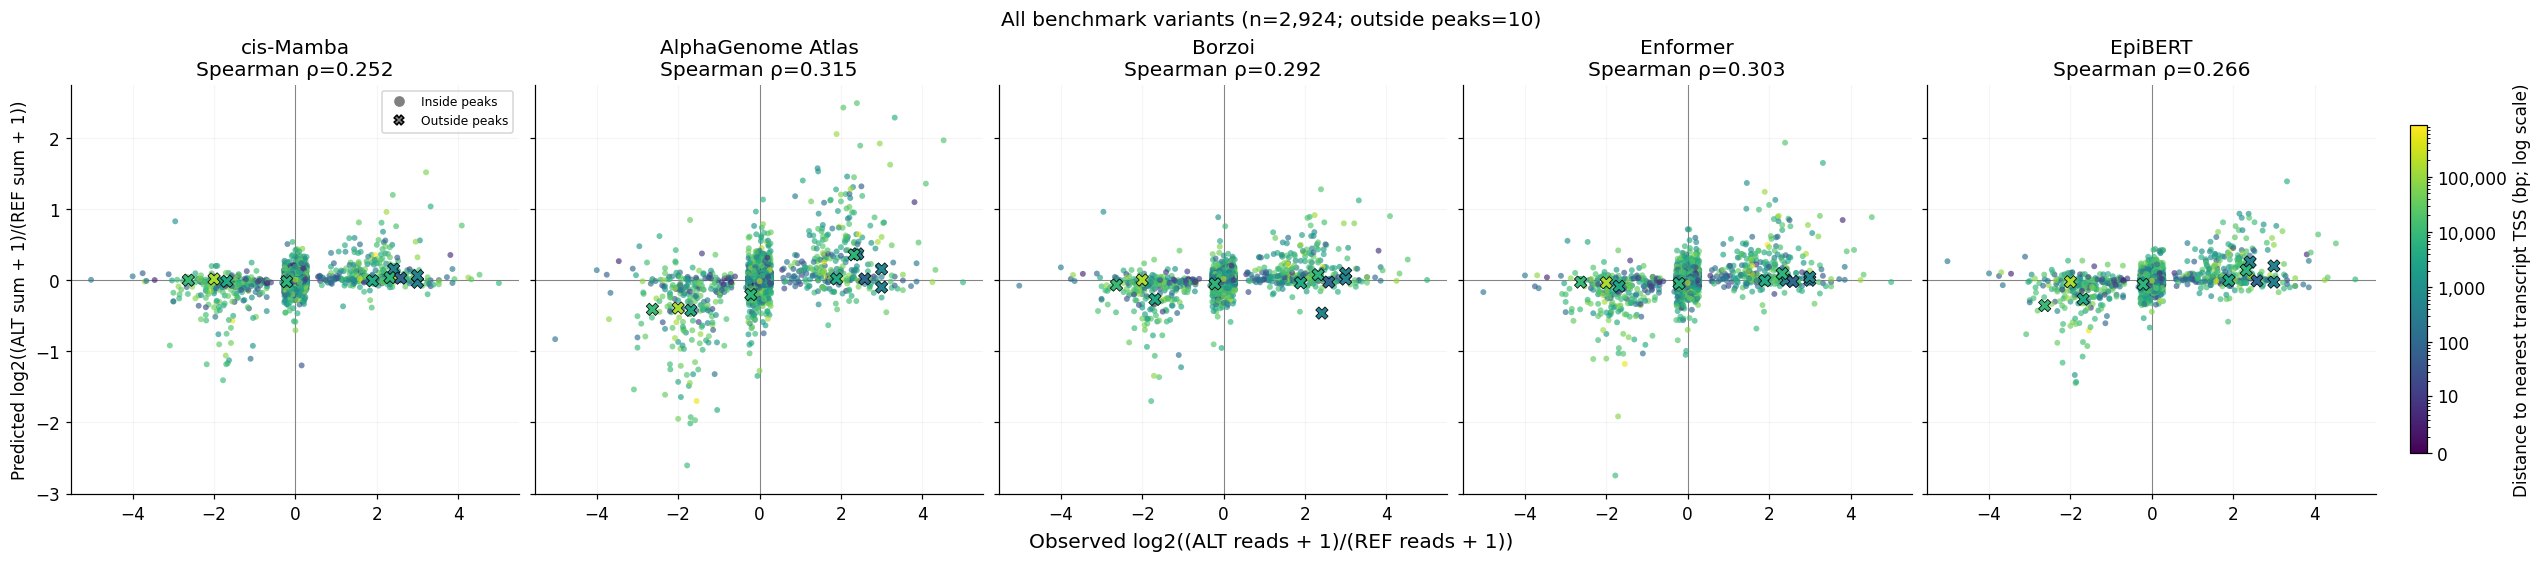

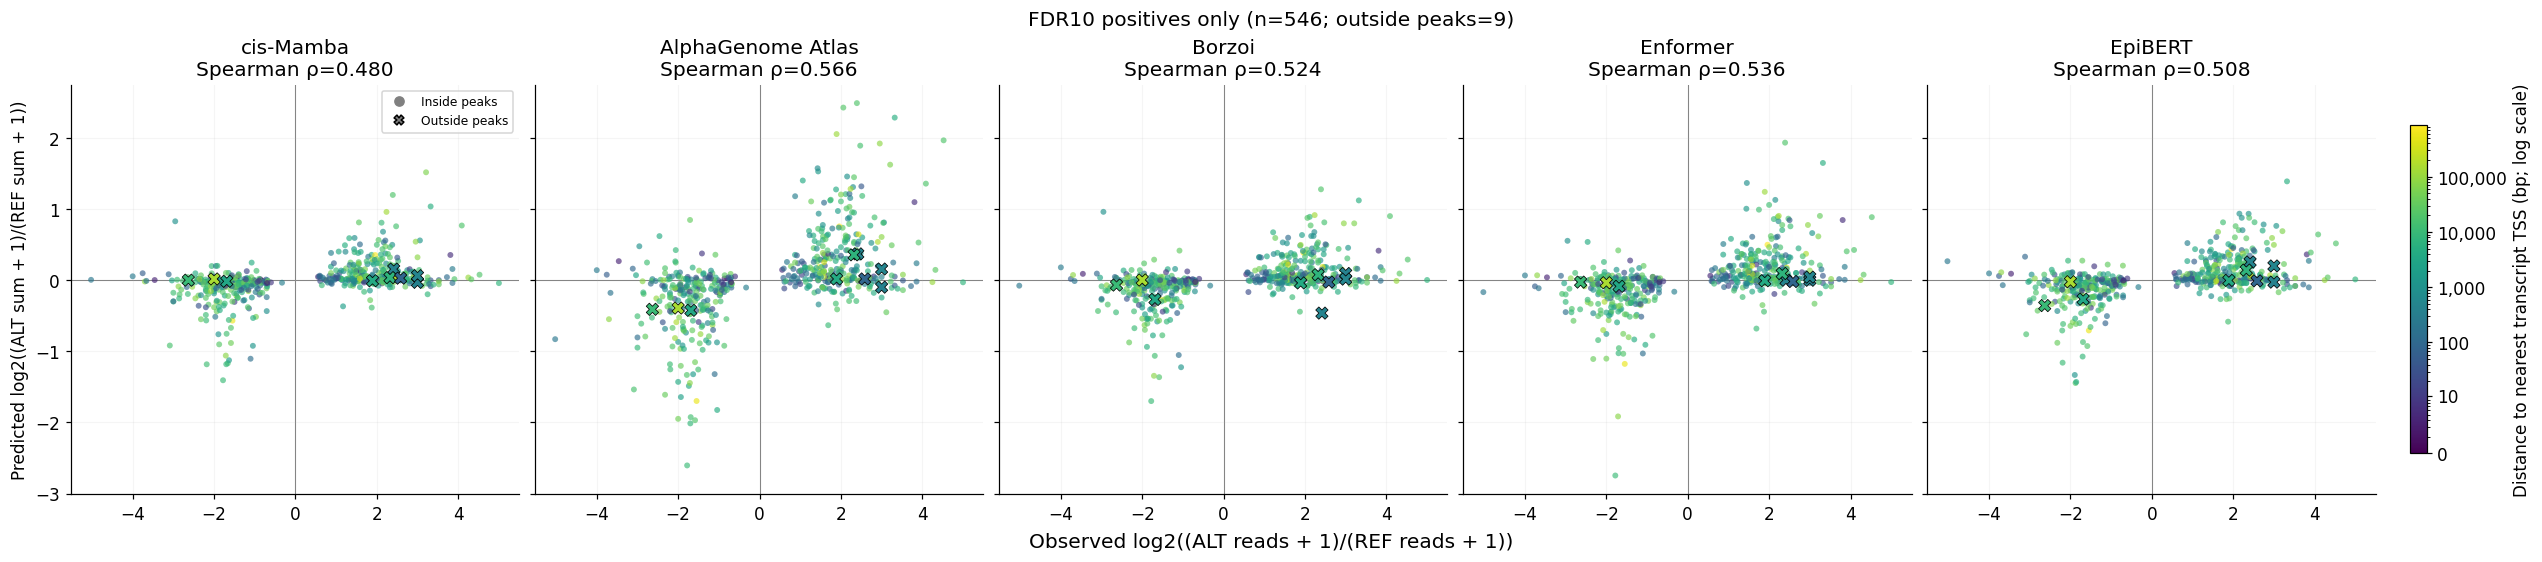

,Model,AlphaGenome Atlas,Borzoi,Enformer,EpiBERT,cis-Mamba
Subset,n,,,,,
All benchmark variants,2924,0.315,0.292,0.303,0.266,0.252
FDR10 positives,546,0.566,0.524,0.536,0.508,0.480
FDR10 positives inside peaks,537,0.566,0.533,0.542,0.507,0.484
FDR10 positives outside peaks,9,0.594,0.485,0.695,0.527,0.243
"FDR10 positives, equal dosage in all observations",495,0.603,0.547,0.564,0.532,0.507


In [8]:
distance_norm = LogNorm(vmin=1, vmax=max(2, int(tss_distance.max()) + 1))
equal_dosage = v.all_bad1.astype(str).str.lower().isin(['true', '1']).to_numpy()

def effect_scatter(mask, title):
    fig, axes = plt.subplots(1, 5, figsize=(23, 5), sharex=True, sharey=True,
                             layout='constrained')
    for ax, name in zip(axes, RUNS):
        predicted = central_signed[name].to_numpy()
        for in_peak, marker, size in [(True, 'o', 15), (False, 'X', 65)]:
            take = mask & (inside == in_peak)
            ax.scatter(observed_signed[take], predicted[take], c=tss_distance[take] + 1,
                       norm=distance_norm, cmap='viridis', marker=marker, s=size,
                       alpha=.65 if in_peak else 1, linewidths=.5 if not in_peak else 0,
                       edgecolors='black' if not in_peak else 'none',
                       zorder=3 if not in_peak else 2)
        rho = spearmanr(observed_signed[mask], predicted[mask]).statistic
        ax.axhline(0, color='gray', lw=.7, zorder=0)
        ax.axvline(0, color='gray', lw=.7, zorder=0)
        ax.set_title(f'{name}\nSpearman ρ={rho:.3f}')
        ax.grid(alpha=.12)
    axes[0].set_ylabel('Predicted log2((ALT sum + 1)/(REF sum + 1))')
    fig.supxlabel('Observed log2((ALT reads + 1)/(REF reads + 1))')
    fig.suptitle(f'{title} (n={mask.sum():,}; outside peaks={(mask & ~inside).sum()})')
    colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=distance_norm, cmap='viridis'),
                           ax=axes, shrink=.8, pad=.015)
    ticks = [d for d in [0, 10, 100, 1000, 10000, 100000, 1000000] if d <= tss_distance.max()]
    colorbar.set_ticks(np.array(ticks) + 1)
    colorbar.set_ticklabels([f'{d:,}' for d in ticks])
    colorbar.set_label('Distance to nearest transcript TSS (bp; log scale)')
    axes[0].legend(handles=[
        Line2D([], [], color='gray', marker='o', ls='', label='Inside peaks'),
        Line2D([], [], color='gray', marker='X', markeredgecolor='black', ls='', label='Outside peaks')
    ], fontsize=8, loc='best')
    plt.show()

effect_scatter(np.ones(len(v), dtype=bool), 'All benchmark variants')
effect_scatter(y == 1, 'FDR10 positives only')

correlation_rows = []
for group, mask in {
    'All benchmark variants': np.ones(len(v), dtype=bool),
    'FDR10 positives': y == 1,
    'FDR10 positives, equal dosage in all observations': (y == 1) & equal_dosage,
    'FDR10 positives inside peaks': (y == 1) & inside,
    'FDR10 positives outside peaks': (y == 1) & ~inside,
}.items():
    for name in RUNS:
        correlation_rows.append({'Subset': group, 'Model': name, 'n': int(mask.sum()),
            'Spearman rho': spearmanr(observed_signed[mask], central_signed[name].to_numpy()[mask]).statistic})
correlations = pd.DataFrame(correlation_rows)
display(correlations.pivot(index=['Subset', 'n'], columns='Model', values='Spearman rho').round(3))

The panels share axis limits and color normalization; no variants are clipped or removed. The positives-only plot avoids correlations being dominated by deliberately balanced controls. The outside-peak positive subset contains only nine variants, so its correlation is descriptive. Read sampling, unequal dosage, and selecting a single representative sample can affect observed ratios; predicted track units also differ between models. EpiBERT remains an ATAC prediction. These plots assess signed association, not absolute calibration of predicted effects to allelic read ratios.

## Accessibility cutoff sweep: allelic-imbalance classification

Repeat the dsQTL/caQTL cutoff plot on this notebook's **FDR10-positive versus
selected matched-control classification benchmark**, using absolute predicted
effects and **AUPRC (average precision)**. This is not the observed-versus-predicted
signed-effect correlation plotted immediately above.

At each cutoff **k**, Specific contains variants in GM12878 merged DNase peaks
with breadth **≤ k**, and Generic contains those with breadth **> k**. Variants
outside these peaks are excluded from both panels. All five models and both
scoring conventions use exactly the same fixed in-peak population. Retain the
source labels, including unequal-dosage positives, as in the original benchmark.
Breadth counts experimental **tracks**, including replicates, not unique cell types.

Two figures retain the notebook's existing score comparisons: **native run
scores**, then **central 500–512 bp with +1 after summing** (Atlas stays at its
native 501 bp). No scoring definition or threshold is selected using outcomes.
The x axis runs from 674 to 1 on a log scale; every integer cutoff is evaluated.
Counts above each panel show positives and negatives at selected cutoffs. The
original cutoff 68 and the changing positive-fraction baseline are marked.

**Matching caveat:** positives and controls are assigned by their own peak breadth,
as in the earlier notebook panels. Original controls were selected within the
coarse peak categories and on coverage/accessibility covariates. New cutoffs can
split an original positive–control set; this sweep does not rematch controls or
claim complete matching at every threshold. The exported counts include controls
whose matched positive falls on the opposite side of the current cutoff. AP
describes this selected cohort, not genome-wide precision.

Dotted segments flag fewer than 20 positives or negatives, solely as a display
aid. Empty/single-class groups have undefined AP and are blank. Nested cutoffs
are not independent holdouts; these descriptive plots have no confidence bands.
Any subsequent uncertainty calculation should account for shared loci and matched
controls. Run the initial data, annotation and score cells through the central
window comparison before these cells; the TSS/scatterplot section is not required.
All outputs are saved in `allelic_effect_prediction_cutoff_sweep/`, using existing
predictions without inference or API calls.


In [6]:
from time import perf_counter

sweep_started = perf_counter()
SWEEP_MODELS = list(RUNS)
SWEEP_MIN_CLASS_COUNT = 20
SWEEP_OUT = ROOT / 'notebooks/benchmarks/dsqtl/allelic_effect_prediction_cutoff_sweep'
SWEEP_OUT.mkdir(exist_ok=True)
SWEEP_SCORES = {'native': native_signed, 'central': central_signed}
SWEEP_TITLES = {'native': 'Native run scores', 'central': 'Central 500–512 bp, +1 pseudocount'}
sweep_track_count = len(pd.read_csv(PEAKS.parent / 'tracks.tsv', sep='\t'))

# Reconstruct numeric breadth/peak IDs from interval overlap, independently of
# the source benchmark's cached categories and row ordering in the peak table.
sweep_breadth = np.full(len(v), np.nan)
sweep_peak_id = np.full(len(v), '', dtype=object)
for chrom, rows in v.groupby('chrom'):
    p = peaks.loc[peaks.chrom == chrom].sort_values('start')
    if p.empty:
        continue
    assert np.all(p.start.to_numpy()[1:] >= p.end.to_numpy()[:-1])
    positions = rows.pos0.to_numpy()
    idx = np.searchsorted(p.start.to_numpy(), positions, side='right') - 1
    overlaps = (idx >= 0) & (positions < p.end.to_numpy()[np.maximum(idx, 0)])
    ids = rows.index.to_numpy()[overlaps]
    sweep_breadth[ids] = p.breadth.to_numpy()[idx[overlaps]]
    sweep_peak_id[ids] = p.peak_id.to_numpy()[idx[overlaps]]
sweep_support = sweep_peak_id != ''
np.testing.assert_array_equal(sweep_support, MASKS['Generic'] | MASKS['Cell-type-specific'])
np.testing.assert_allclose(sweep_breadth[sweep_support], v.loc[sweep_support, 'peak_breadth'])
np.testing.assert_array_equal(sweep_peak_id[sweep_support], v.loc[sweep_support, 'peak_id'])
assert np.isfinite(sweep_breadth[sweep_support]).all()
assert ((sweep_breadth[sweep_support] >= 1) &
        (sweep_breadth[sweep_support] <= sweep_track_count)).all()
assert (sweep_breadth[sweep_support] == np.floor(sweep_breadth[sweep_support])).all()
np.testing.assert_array_equal(sweep_support & (sweep_breadth <= 68), MASKS['Cell-type-specific'])
np.testing.assert_array_equal(sweep_support & (sweep_breadth > 68), MASKS['Generic'])
for signed in SWEEP_SCORES.values():
    assert signed.index.equals(pd.Index(v.variant_id))
    assert set(SWEEP_MODELS) <= set(signed)
    assert np.isfinite(signed[SWEEP_MODELS].to_numpy()).all()

# Track when the original matching is split, without changing control selection.
assert v.loc[y == 1, 'rsid'].is_unique
positive_breadth = pd.Series(sweep_breadth[y == 1], index=v.loc[y == 1, 'rsid'])
negative_in_peak = sweep_support & (y == 0)
assert v.loc[negative_in_peak, 'matched_positive_rsid'].isin(positive_breadth.index).all()
sweep_matched_positive_breadth = v.matched_positive_rsid.map(positive_breadth).to_numpy()
assert np.isfinite(sweep_matched_positive_breadth[negative_in_peak]).all()
sweep_magnitudes = {definition: signed[SWEEP_MODELS].abs().to_numpy()
                    for definition, signed in SWEEP_SCORES.items()}
sweep_count_rows, sweep_score_rows = [], []
for cutoff in range(1, sweep_track_count + 1):
    for group, mask in [('Specific', sweep_support & (sweep_breadth <= cutoff)),
                        ('Generic', sweep_support & (sweep_breadth > cutoff))]:
        n = int(mask.sum())
        positive = int(y[mask].sum())
        negative = n - positive
        defined = positive > 0 and negative > 0
        opposite = (sweep_matched_positive_breadth > cutoff if group == 'Specific'
                    else sweep_matched_positive_breadth <= cutoff)
        sweep_count_rows.append(dict(cutoff=cutoff, group=group, variants=n,
            positives=positive, negatives=negative,
            prevalence=positive / n if n else np.nan, ap_defined=defined,
            low_count=min(positive, negative) < SWEEP_MIN_CLASS_COUNT,
            peak_clusters=int(pd.Series(sweep_peak_id[mask]).nunique()),
            controls_with_positive_in_other_group=int((mask & (y == 0) & opposite).sum())))
        for definition, magnitudes in sweep_magnitudes.items():
            for i, name in enumerate(SWEEP_MODELS):
                ap = average_precision_score(y[mask], magnitudes[mask, i]) if defined else np.nan
                sweep_score_rows.append(dict(cutoff=cutoff, group=group,
                    scoring=definition, model=name, ap=ap))

sweep_counts = pd.DataFrame(sweep_count_rows)
sweep_results = pd.DataFrame(sweep_score_rows).merge(
    sweep_counts, on=['cutoff', 'group'], validate='many_to_one')
assert sweep_counts.groupby('cutoff').variants.sum().eq(int(sweep_support.sum())).all()
assert sweep_counts.groupby('cutoff').positives.sum().eq(int(y[sweep_support].sum())).all()
assert sweep_counts.loc[sweep_counts.cutoff == 68, 'controls_with_positive_in_other_group'].eq(0).all()
for definition, reference_ap in [('native', native_ap), ('central', central_ap)]:
    for group, old_group in [('Specific', 'Cell-type-specific'), ('Generic', 'Generic')]:
        subset = sweep_results[(sweep_results.cutoff == 68) & (sweep_results.group == group) &
                               (sweep_results.scoring == definition)].set_index('model')
        np.testing.assert_allclose(subset.loc[SWEEP_MODELS, 'ap'],
                                  reference_ap.loc[SWEEP_MODELS, old_group], atol=1e-12, rtol=0)
sweep_counts.to_csv(SWEEP_OUT / 'cutoff_counts.tsv', sep='\t', index=False)
sweep_results.to_csv(SWEEP_OUT / 'cutoff_model_ap.tsv', sep='\t', index=False)
(SWEEP_OUT / 'config.json').write_text(json.dumps({
    'models': SWEEP_MODELS, 'cutoffs': [1, sweep_track_count],
    'score_conventions': SWEEP_TITLES,
    'native_definitions': native_definitions.to_dict(orient='index'),
    'central_formula': 'abs(log2((ALT sum + 1)/(REF sum + 1))); Atlas native 501 bp',
    'central_windows': WINDOWS, 'runs': RUNS,
    'input_sha256': input_sha256, 'peak_table': str(PEAKS),
    'peak_table_sha256': hashlib.sha256(PEAKS.read_bytes()).hexdigest(),
    'support': 'fixed pilot cohort, within GM12878 merged peaks, all models finite',
    'grouping': 'each variant own peak breadth; specific <=k; generic >k',
    'matching': 'original controls retained; new cutoffs can split positive-control sets',
    'metric': 'sklearn.metrics.average_precision_score',
    'original_cutoff': 68, 'low_count_display_threshold_per_class': SWEEP_MIN_CLASS_COUNT,
    'confidence_intervals': False,
}, indent=2) + '\n')
SWEEP_COUNT_TICKS = sorted({1, 5, 20, 68, 200, sweep_track_count})
display(sweep_counts[sweep_counts.cutoff.isin(SWEEP_COUNT_TICKS)]
        .sort_values(['group', 'cutoff'], ascending=[False, False]))
print(f'Computed {sweep_track_count} cutoffs, {len(SWEEP_MODELS)} models and '
      f'{len(SWEEP_SCORES)} score definitions in {perf_counter() - sweep_started:.1f} s. '
      f'Fixed in-peak population: {sweep_support.sum():,} variants, '
      f'{int(y[sweep_support].sum()):,} positives; excluded {(~sweep_support).sum():,} outside peaks. '
      f'Both score definitions reproduce the original cutoff-68 AP. Outputs: {SWEEP_OUT}')


,cutoff,group,variants,positives,negatives,prevalence,ap_defined,low_count,peak_clusters,controls_with_positive_in_other_group
1346,674,Specific,2914,537,2377,0.184283,True,False,2453,0
398,200,Specific,793,222,571,0.279950,True,False,674,210
134,68,Specific,268,68,200,0.253731,True,False,229,0
38,20,Specific,43,11,32,0.255814,True,True,37,24
8,5,Specific,3,2,1,0.666667,True,True,3,1
0,1,Specific,1,1,0,1.000000,False,True,1,0
1347,674,Generic,0,0,0,NaN,False,True,0,0
399,200,Generic,2121,315,1806,0.148515,True,False,1779,516
135,68,Generic,2646,469,2177,0.177249,True,False,2224,0
39,20,Generic,2871,526,2345,0.183211,True,False,2416,35


Computed 674 cutoffs, 5 models and 2 score definitions in 10.3 s. Fixed in-peak population: 2,914 variants, 537 positives; excluded 10 outside peaks. Both score definitions reproduce the original cutoff-68 AP. Outputs: /data1/lesliec/sarthak/caduceus/notebooks/benchmarks/dsqtl/allelic_effect_prediction_cutoff_sweep


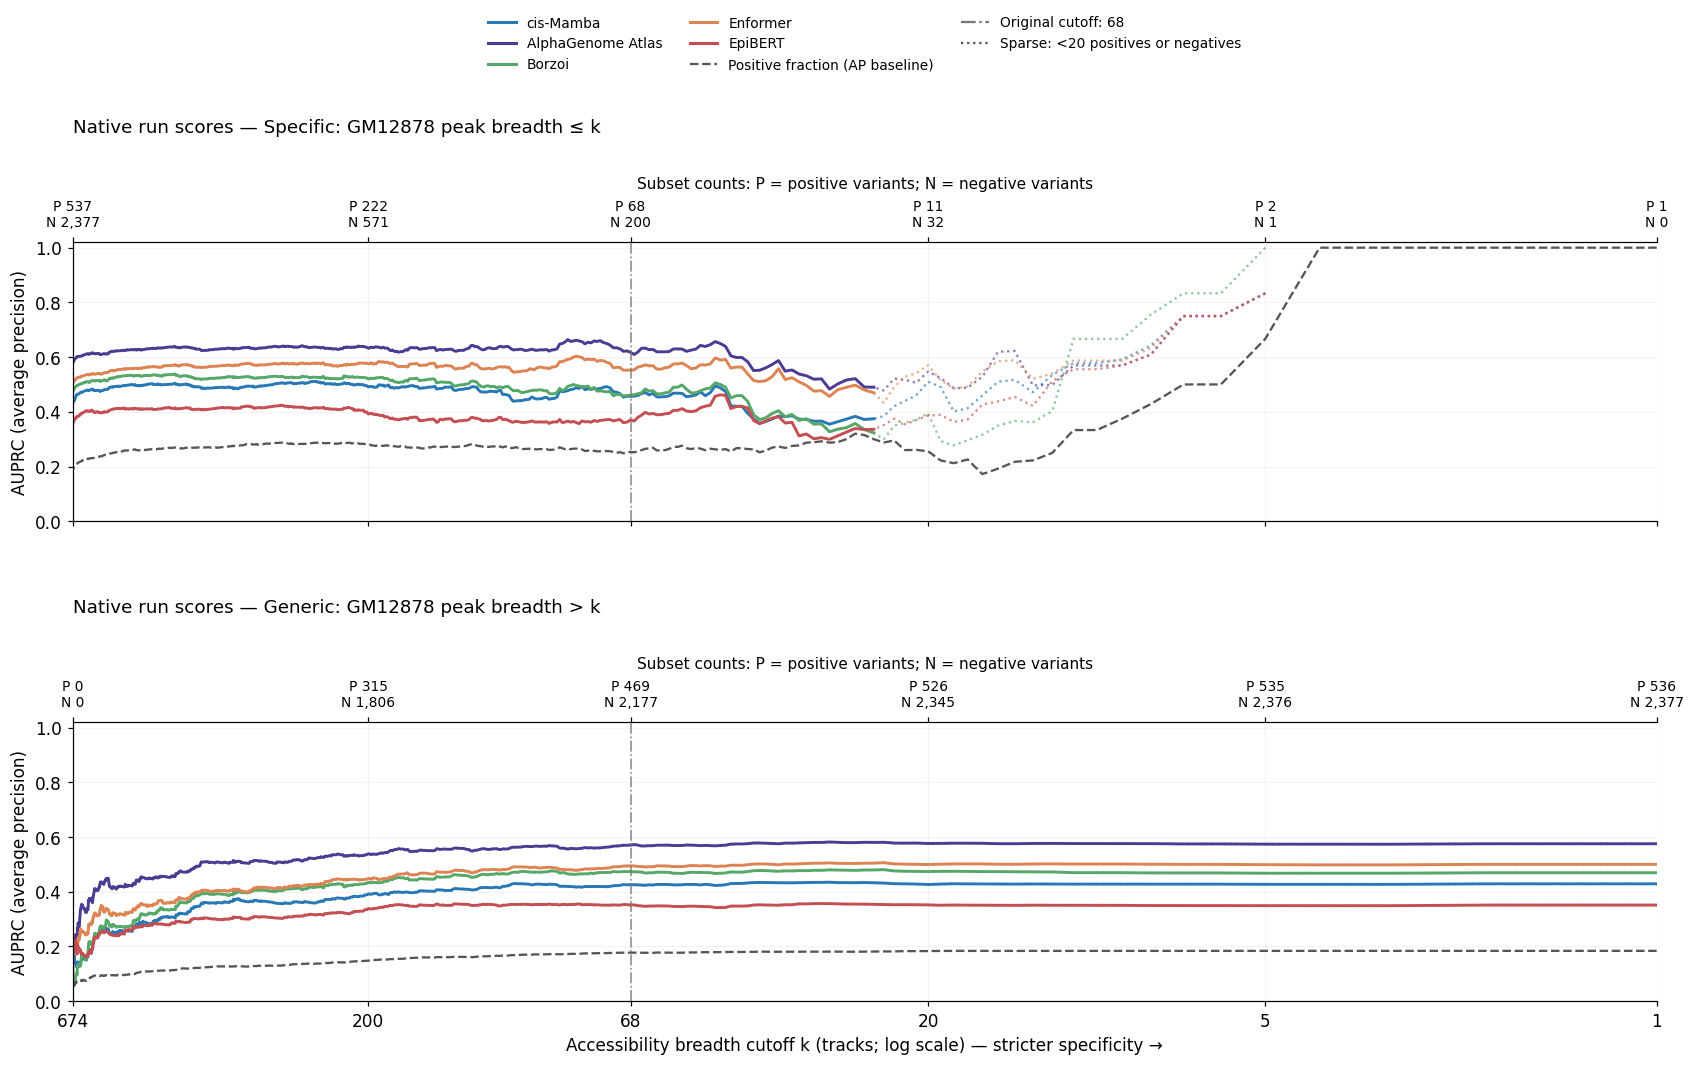

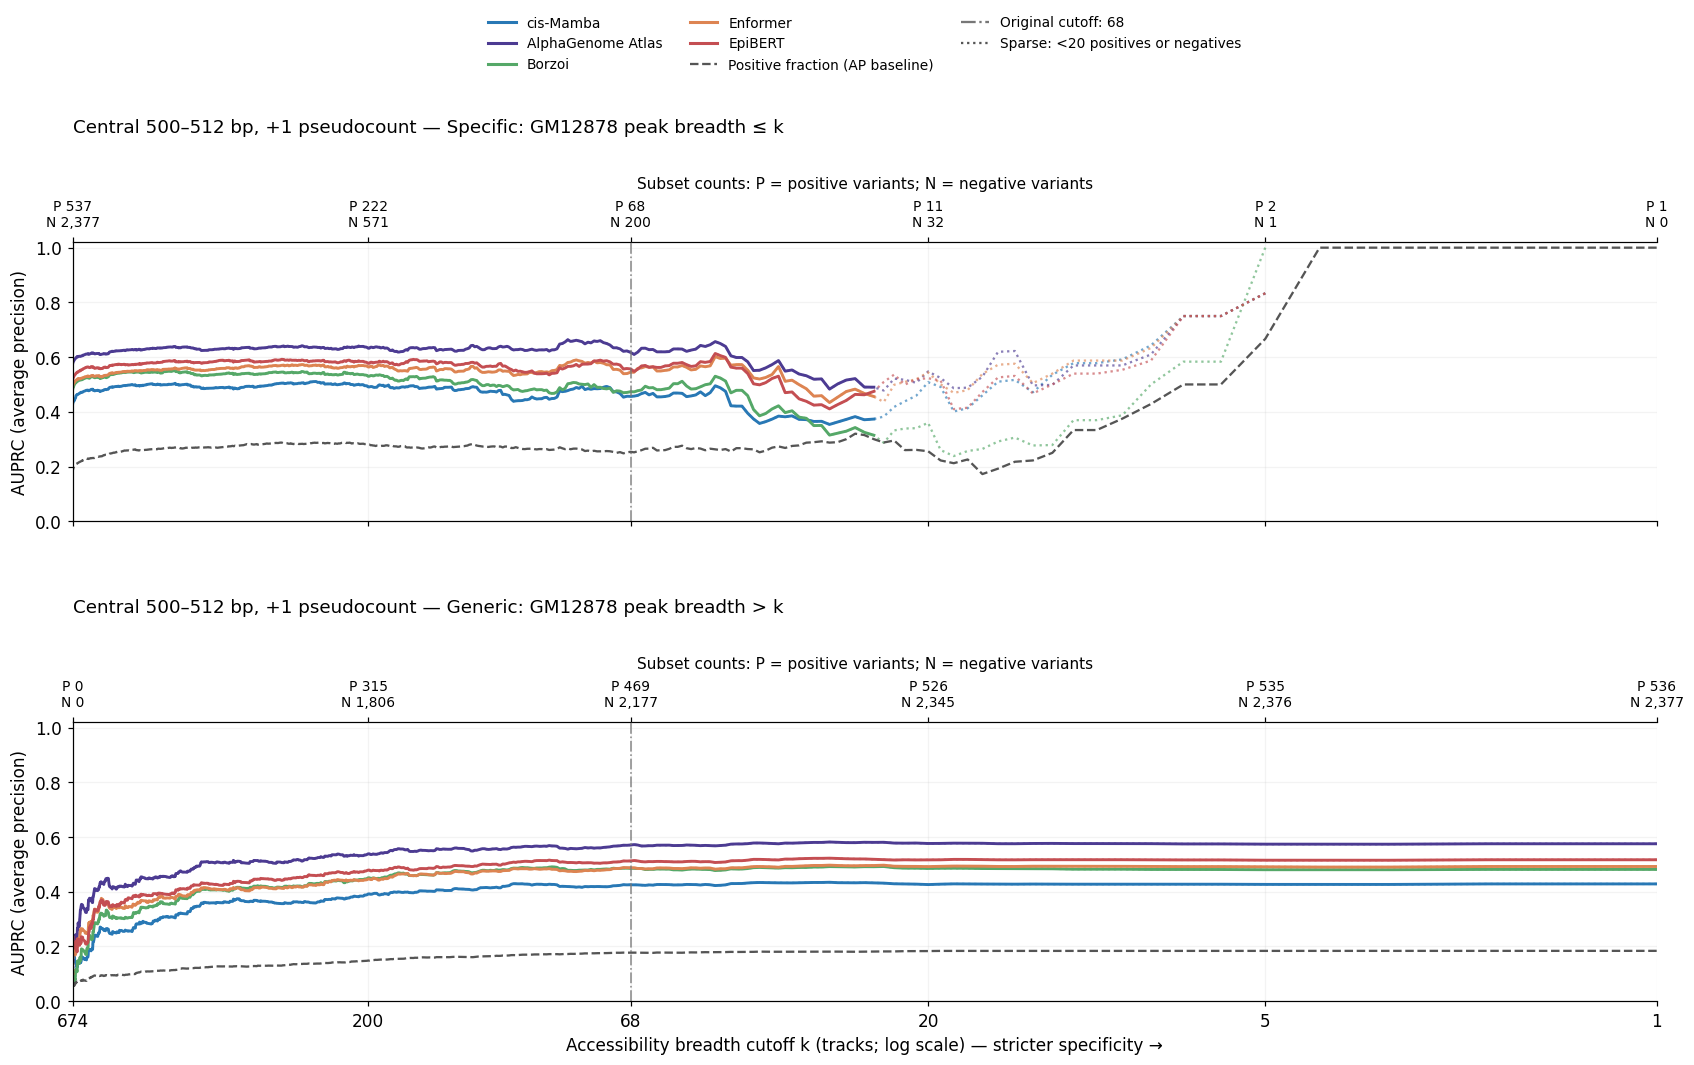

In [7]:
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator
from matplotlib.lines import Line2D

def plot_allelic_cutoff_sweep(definition):
    sweep_colors = COLORS
    fig, sweep_axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True, sharey=True)
    fig.subplots_adjust(left=.08, right=.98, bottom=.09, top=.78, hspace=.72)

    for ax, group, rule in zip(sweep_axes, ['Specific', 'Generic'], ['≤ k', '> k']):
        count = sweep_counts[sweep_counts.group == group].sort_values('cutoff').set_index('cutoff')
        for name in SWEEP_MODELS:
            data = sweep_results[(sweep_results.group == group) &
                                 (sweep_results.model == name) & (sweep_results.scoring == definition)].sort_values('cutoff')
            # A faint dotted trace displays supported but sparse estimates; the
            # solid overlay identifies portions with >=20 observations per class.
            ax.plot(data.cutoff, data.ap, color=sweep_colors[name], lw=1.5,
                    ls=':', alpha=.65)
            ax.plot(data.cutoff, data.ap.where(~data.low_count),
                    color=sweep_colors[name], lw=1.9, label=name)
        ax.plot(count.index, count.prevalence, color='#555555', ls='--', lw=1.5)
        ax.axvline(68, color='#777777', ls='-.', lw=1.1, alpha=.8)
        ax.set_xscale('log')
        ax.set_xlim(sweep_track_count, 1)
        ax.set_ylim(0, 1.02)
        ax.set_ylabel('AUPRC (average precision)')
        ax.set_title(f'{SWEEP_TITLES[definition]} — {group}: GM12878 peak breadth {rule}', loc='left', pad=72, fontsize=12)
        ax.xaxis.set_major_locator(FixedLocator(SWEEP_COUNT_TICKS))
        ax.xaxis.set_major_formatter(FixedFormatter([str(k) for k in SWEEP_COUNT_TICKS]))
        ax.xaxis.set_minor_locator(NullLocator())
        ax.grid(alpha=.15)
        ax.set_axisbelow(True)
        count_axis = ax.secondary_xaxis('top')
        count_axis.xaxis.set_major_locator(FixedLocator(SWEEP_COUNT_TICKS))
        count_axis.xaxis.set_major_formatter(FixedFormatter([
            f'P {int(count.loc[k, "positives"]):,}\nN {int(count.loc[k, "negatives"]):,}'
            for k in SWEEP_COUNT_TICKS]))
        count_axis.xaxis.set_minor_locator(NullLocator())
        count_axis.tick_params(axis='x', labelsize=9, pad=5)
        count_axis.set_xlabel('Subset counts: P = positive variants; N = negative variants',
                              fontsize=10, labelpad=7)

    sweep_axes[-1].set_xlabel('Accessibility breadth cutoff k (tracks; log scale) — stricter specificity →')
    handles = [Line2D([], [], color=sweep_colors[n], lw=2, label=n) for n in SWEEP_MODELS]
    handles += [Line2D([], [], color='#555555', ls='--', label='Positive fraction (AP baseline)'),
                Line2D([], [], color='#777777', ls='-.', label='Original cutoff: 68'),
                Line2D([], [], color='#555555', ls=':', label='Sparse: <20 positives or negatives')]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(.53, .997),
               ncol=3, fontsize=9, frameon=False)
    fig.savefig(SWEEP_OUT / f'accessibility_cutoff_sweep_{definition}.png', dpi=180, bbox_inches='tight')
    fig.savefig(SWEEP_OUT / f'accessibility_cutoff_sweep_{definition}.pdf', bbox_inches='tight')
    plt.show()

plot_allelic_cutoff_sweep('native')
plot_allelic_cutoff_sweep('central')
